# 1 NumPy

In [1]:
import numpy as np

a = np.array([2, 3, 4])
B = np.array([[1.2, 2, 4], [3.1, 4.0, 5]])

print(a.ndim)      # Ilość wymiarów tablicy
print(a.shape)     # Kształt tablicy reprezentowany jako tuple
print(a.size)      # Całkowita ilość elementów
print(a.dtype)     # Typ elementów
print(a.itemsize)  # Wielkość elementu w bajtach

print(B.ndim)
print(B.shape)
print(B.size)
print(B.dtype)
print(B.itemsize)

dir(a)

1
(3,)
3
int64
8
2
(2, 3)
6
float64
8


['T',
 '__abs__',
 '__add__',
 '__and__',
 '__array__',
 '__array_finalize__',
 '__array_function__',
 '__array_interface__',
 '__array_namespace__',
 '__array_priority__',
 '__array_struct__',
 '__array_ufunc__',
 '__array_wrap__',
 '__bool__',
 '__class__',
 '__class_getitem__',
 '__complex__',
 '__contains__',
 '__copy__',
 '__deepcopy__',
 '__delattr__',
 '__delitem__',
 '__dir__',
 '__divmod__',
 '__dlpack__',
 '__dlpack_device__',
 '__doc__',
 '__eq__',
 '__float__',
 '__floordiv__',
 '__format__',
 '__ge__',
 '__getattribute__',
 '__getitem__',
 '__gt__',
 '__hash__',
 '__iadd__',
 '__iand__',
 '__ifloordiv__',
 '__ilshift__',
 '__imatmul__',
 '__imod__',
 '__imul__',
 '__index__',
 '__init__',
 '__init_subclass__',
 '__int__',
 '__invert__',
 '__ior__',
 '__ipow__',
 '__irshift__',
 '__isub__',
 '__iter__',
 '__itruediv__',
 '__ixor__',
 '__le__',
 '__len__',
 '__lshift__',
 '__lt__',
 '__matmul__',
 '__mod__',
 '__mul__',
 '__ne__',
 '__neg__',
 '__new__',
 '__or__',
 '__pos__

## 1.1 Czas operacji

In [2]:
import timeit


def sum_own(lst):
    total_sum = 0

    for elem in lst:
        total_sum += elem

    return total_sum


n = 1_000_000

lst = list(range(n))  # [0, 1, ..., n-1]
arr = np.arange(n)    # [0; 1; ...; n-1]

number = 100
repeat = 5

arr_times = timeit.repeat(
    "arr.sum()",
    globals=globals(),
    number=number,
    repeat=repeat,
)

lst_times = timeit.repeat(
    "sum(lst)",
    globals=globals(),
    number=number,
    repeat=repeat
)

lst_own_times = timeit.repeat(
    "sum_own(lst)",
    globals=globals(),
    number=number,
    repeat=repeat
)

print(sum(arr_times) / (number * repeat))
print(sum(lst_times) / (number * repeat))
print(sum(lst_own_times) / (number * repeat))

0.0005261039580072975
0.004788113178001367
0.03789790870199795


## 1.2 Tworzenie tablic

In [3]:
C = np.ones((3, 2))  # np.zeros, np.ones, np.empty
d = np.linspace(start=0, stop=1, num=6)

print(C)
print(d)

[[1. 1.]
 [1. 1.]
 [1. 1.]]
[0.  0.2 0.4 0.6 0.8 1. ]


## 1.3 Podstawowe operacje

In [4]:
E = B - 1
F = E * 2

# * - Gwiazdka to iloczyn Hadamarda
# @ - Małpa to mnożenie macierzy Cauchy'ego

print(E)
print(F)
print(B.tolist() * 2)

print(B.min())        # Najmniejsza wartość
print(B.max())        # Największa wartość
print(B.sum())        # Suma elementów
print(B.sum(axis=0))  # Suma dla każdej kolumny
print(B.sum(axis=1))  # Suma dla każdego wiersza

[[0.2 1.  3. ]
 [2.1 3.  4. ]]
[[0.4 2.  6. ]
 [4.2 6.  8. ]]
[[1.2, 2.0, 4.0], [3.1, 4.0, 5.0], [1.2, 2.0, 4.0], [3.1, 4.0, 5.0]]
1.2
5.0
19.3
[4.3 6.  9. ]
[ 7.2 12.1]


### 1.3.1 Zadanie do wykonania

In [5]:
print(E * B)
print(E @ C)

[[ 0.24  2.   12.  ]
 [ 6.51 12.   20.  ]]
[[4.2 4.2]
 [9.1 9.1]]


## 1.4 Kształt tablicy

In [6]:
from numpy.linalg import inv, det

print(d[2])     # Element o indeksie 2
print(d[-1])    # Ostatni element
print(B[1][2])  # Wiersz o indeksie 1, kolumna o indeksie 2
print(d[2:5])   # Od elementu 2 (razem z 2) do 5 (bez 5)
print(d[2:])    # Od elementu 2 (razem z 2)
print(d[:2])    # Pierwsze dwa elementy

print(B.flatten())             # Spłaszczenie do wektora
print(B.reshape(6, 1))         # Zmiana kształtu na podany
print(B.T)                     # Transpozycja
print(np.hsplit(B, 3))         # Podział poziomy
print(np.vstack((a, a - 1)))   # Złożenie pionowe
print(np.hstack((a, a * -1)))  # Złożenie poziome

print(inv(B @ B.T))  # Odwrotność macierzy
print(det(B.T @ B))  # Wyznacznik macierzy

0.4
1.0
5.0
[0.4 0.6 0.8]
[0.4 0.6 0.8 1. ]
[0.  0.2]
[1.2 2.  4.  3.1 4.  5. ]
[[1.2]
 [2. ]
 [4. ]
 [3.1]
 [4. ]
 [5. ]]
[[1.2 3.1]
 [2.  4. ]
 [4.  5. ]]
[array([[1.2],
       [3.1]]), array([[2.],
       [4.]]), array([[4.],
       [5.]])]
[[2 3 4]
 [1 2 3]]
[ 2  3  4 -2 -3 -4]
[[ 0.64128231 -0.401926  ]
 [-0.401926    0.27166751]]
-1.2335021892795278e-13


### 1.4.1 Zadania do wykonania

In [7]:
d = d.reshape(3, 2)
print(d @ B)

t = np.arange(2, 8)
print(t[t % 2 == 0].sum())

temps = np.random.normal(
    loc=np.linspace(278, 303, 7)[:, None],
    scale=8,
    size=(7, 4)
)
temps[[1, 3], [2, 3]] = 0

temps_del = temps[temps > 0]
print(temps.shape)
print(temps_del.shape)

print(temps)
for day in temps:
    day[day == 0] = day[day != 0].mean()

temps = temps - 273.15
print(temps)

print(f"Ilość pomiarów większych od 25°C: {(temps > 25).sum()}")
print(f"Ilość pomiarów mniejszych od 0°C: {(temps < 0).sum()}")

[[0.62 0.8  1.  ]
 [2.34 3.2  4.6 ]
 [4.06 5.6  8.2 ]]
12
(7, 4)
(26,)
[[285.43549476 291.02096633 275.64977216 292.14315762]
 [291.92632167 282.11144512   0.         277.51410784]
 [282.45939996 292.64127661 281.24740042 293.08847719]
 [295.45907685 288.72180599 300.7741135    0.        ]
 [300.06882428 314.29398938 300.19767275 281.58268897]
 [313.45816215 298.18472067 295.77386017 291.18996518]
 [302.92428036 312.67729425 296.57389074 309.99260479]]
[[12.28549476 17.87096633  2.49977216 18.99315762]
 [18.77632167  8.96144512 10.70062488  4.36410784]
 [ 9.30939996 19.49127661  8.09740042 19.93847719]
 [22.30907685 15.57180599 27.6241135  21.83499878]
 [26.91882428 41.14398938 27.04767275  8.43268897]
 [40.30816215 25.03472067 22.62386017 18.03996518]
 [29.77428036 39.52729425 23.42389074 36.84260479]]
Ilość pomiarów większych od 25°C: 9
Ilość pomiarów mniejszych od 0°C: 0


# 2 Matplotlib

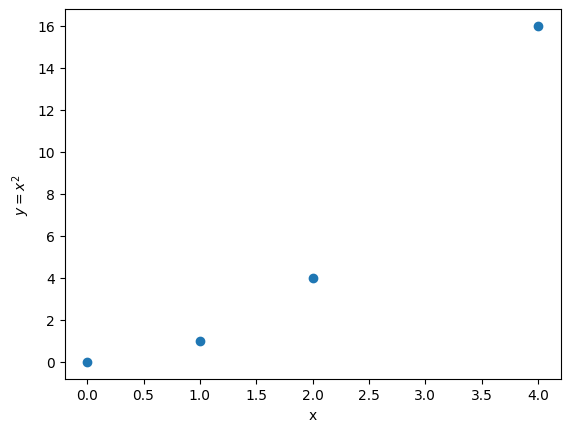

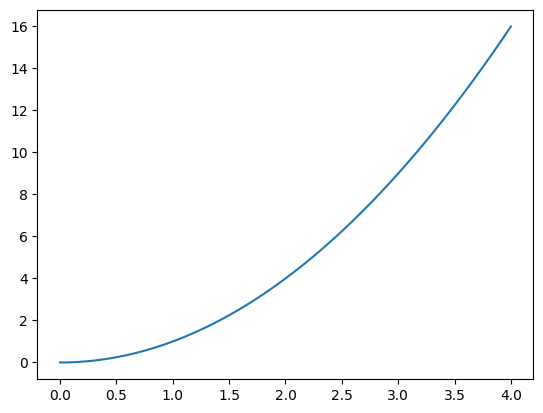

In [8]:
import matplotlib.pyplot as plt

x = [0, 1, 2, 4]
y = [0, 1, 4, 16]

plt.scatter(x, y)
plt.xlabel("x")
plt.ylabel("$y = x^2$")  # LaTeX
plt.show()

x = np.linspace(0, 4, 100)
y = x**2

plt.plot(x, y)
plt.show()

## 2.1 Zadania do wykonania

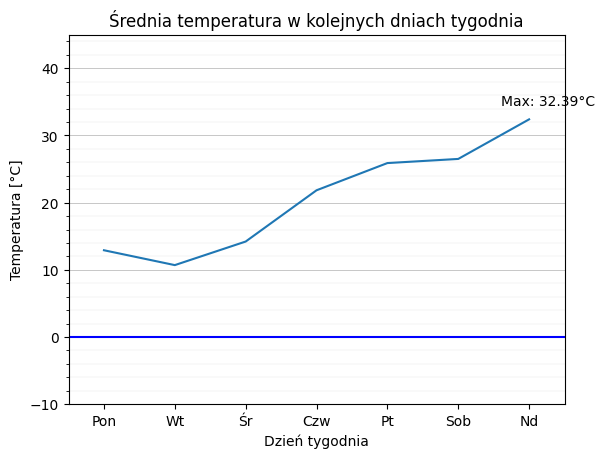

In [9]:
day_avg = temps.mean(axis=1)
days = ["Pon", "Wt", "Śr", "Czw", "Pt", "Sob", "Nd"]
max_temp = day_avg.max()
max_idx = np.argmax(day_avg)

x = range(day_avg.size)
y = day_avg

plt.plot(x, y)
plt.title("Średnia temperatura w kolejnych dniach tygodnia")
plt.xlabel("Dzień tygodnia")
plt.ylabel("Temperatura [°C]")
plt.ylim(-10, 45)
plt.yticks(range(-10, 45, 10), minor=False)
plt.yticks(range(-10, 45, 2), minor=True)
plt.grid(which="major", axis="y", linewidth=0.5)
plt.grid(which="minor", axis="y", linewidth=0.1)
plt.xlim(-0.5, 6.5)
plt.xticks(x, days)
plt.axline((0, 0), slope=0, color="blue")
plt.annotate(
    f"Max: {round(max_temp, 2)}°C",
    xy=(max_idx, max_temp),
    xytext=(-20, 10),
    textcoords="offset points"
)
plt.savefig("temperature.png", dpi=300)
plt.show()